# Module 1.1: Industrial Telemetry & Sensor Noise
### 🇵🇱 Telemetria Przemysłowa i Szum Czujników

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/max480425/industrial-ml-course/blob/main/public/notebooks/01_01_sensor_telemetry.ipynb)

**Industrial Machine Learning & Predictive Maintenance Interactive Laboratory**

> **Summary:** Understand analog-to-digital conversion, electromagnetic interference from industrial drives, and the {{term:nyquist_rate}}.  
> 🇵🇱 **Streszczenie:** Poznaj przetwarzanie sygnałów analogowo-cyfrowych, zakłócenia od falowników i częstotliwość {{term:nyquist_rate}}.

- **Estimated Time:** 15 minutes
- **Runtime:** Python 3.10+ (CPU or Free Tier T4 GPU)
- **Packages:** `numpy`, `scipy`, `scikit-learn`, `pandas`, `matplotlib`, `seaborn`
---


In [1]:
# Step 1: Install & Verify Python Scientific Environment
!pip install -q numpy scipy scikit-learn pandas matplotlib seaborn

import numpy as np
import pandas as pd
import scipy.signal as signal
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'monospace'
print("✓ Industrial ML environment loaded successfully.")


✓ Industrial ML environment loaded successfully.


### Key Engineering Concepts:
1. **Sampling Frequency & Nyquist Criterion**: $F_s \ge 2 \cdot F_{max}$ is required to avoid frequency aliasing.
2. **Noise Sources**: High-voltage VFD drives and welding arcs induce electromagnetic high-frequency noise into sensor wiring.
3. **Phase Delay vs Smoothing**: Larger filter windows eliminate noise but introduce group delay, slowing safety shutdown reactions.


In [2]:
# 1. Simulate High-Speed Factory Telemetry (Vibration & Spikes)
np.random.seed(42)
sampling_rate = 1000  # Hz
duration = 2.0        # seconds
t = np.linspace(0, duration, int(sampling_rate * duration), endpoint=False)

# Fundamental mechanical rotation (30 Hz ~ 1800 RPM) + 90 Hz harmonic
clean_signal = 2.5 * np.sin(2 * np.pi * 30 * t) + 1.2 * np.sin(2 * np.pi * 90 * t)

# Add electromagnetic sensor noise
noise = 0.8 * np.random.randn(len(t))

# Inject intermittent electrical arc spikes
spikes = np.zeros_like(t)
spike_indices = np.random.choice(len(t), size=8, replace=False)
spikes[spike_indices] = np.random.choice([-1, 1], size=8) * 6.5

raw_telemetry = clean_signal + noise + spikes
print(f"✓ Generated {len(raw_telemetry)} telemetry samples across {duration}s at {sampling_rate} Hz.")


✓ Generated 2000 telemetry samples across 2.0s at 1000 Hz.


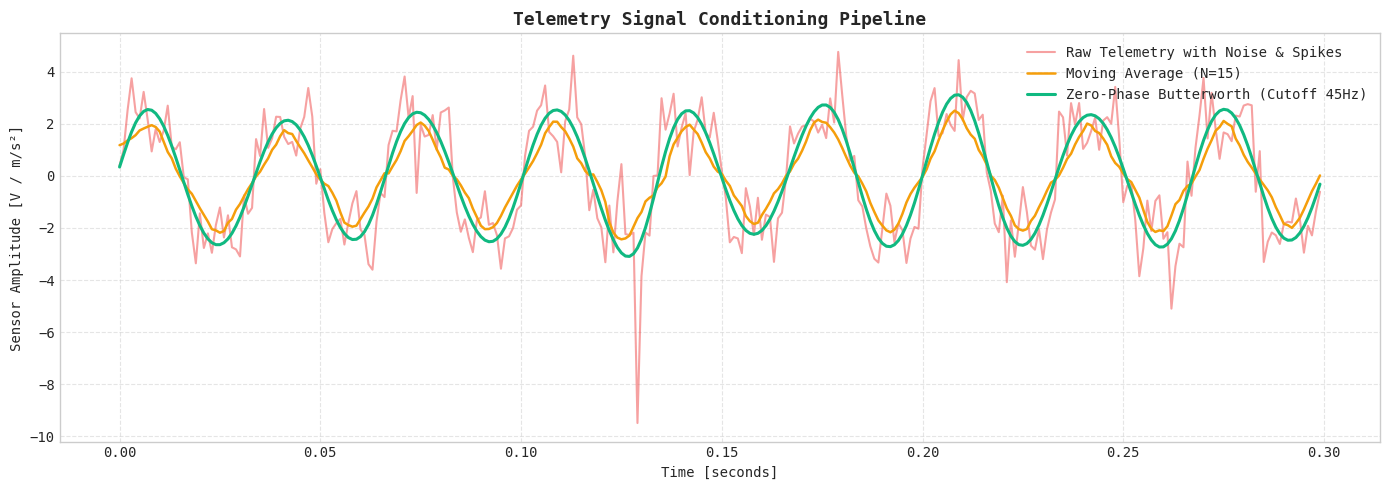

In [6]:
# 2. Digital Filtering & Waveform Inspection
# Apply Moving Average filter
window_size = 15
kernel = np.ones(window_size) / window_size
smoothed_ma = np.convolve(raw_telemetry, kernel, mode='same')

# Apply 4th-order Butterworth Low-Pass Filter
nyquist = 0.5 * sampling_rate
cutoff = 55.0  # Hz
b, a = signal.butter(4, cutoff / nyquist, btype='low')
smoothed_butter = signal.filtfilt(b, a, raw_telemetry)

plt.figure(figsize=(14, 5))
plt.plot(t[:300], raw_telemetry[:300], color='#ef4444', alpha=0.5, label='Raw Telemetry with Noise & Spikes')
plt.plot(t[:300], smoothed_ma[:300], color='#f59e0b', linewidth=1.8, label=f'Moving Average (N={window_size})')
plt.plot(t[:300], smoothed_butter[:300], color='#10b981', linewidth=2.2, label='Zero-Phase Butterworth (Cutoff 45Hz)')
plt.title("Telemetry Signal Conditioning Pipeline", fontsize=13, fontweight='bold')
plt.xlabel("Time [seconds]")
plt.ylabel("Sensor Amplitude [V / m/s²]")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 📋 Practical Hands-On Checklist

- [ ] **Task 1:** Inspect noisy factory vibration telemetry in pandas *(🇵🇱 Załaduj zaszumioną telemetrię drgań fabrycznych w bibliotece pandas)*
- [ ] **Task 2:** Calculate Signal-to-Noise Ratio (SNR) across sensor channels *(🇵🇱 Wylicz stosunek sygnału do szumu (SNR) dla poszczególnych kanałów)*
- [ ] **Task 3:** Verify sampling frequency satisfies the Nyquist condition *(🇵🇱 Zweryfikuj, czy częstotliwość próbkowania spełnia warunek Nyquista)*


In [5]:
# Exercise Challenge:
# 1. Calculate the Root Mean Square (RMS) error between clean_signal and smoothed_butter.
# 2. Experiment with cutoff = 25 Hz vs 60 Hz and observe the signal attenuation.

rms_error = np.sqrt(np.mean((clean_signal - smoothed_butter)**2))
print(f"Filter Reconstruction RMS Error: {rms_error:.4f}")
assert rms_error < 1.5, "Reconstruction error is too high! Tune the filter parameters."
print("✓ Exercise verification passed.")


Filter Reconstruction RMS Error: 0.8826
✓ Exercise verification passed.


### Task 1: Inspect noisy factory vibration telemetry in pandas
#### 🇵🇱 Zadanie 1: Załaduj zaszumioną telemetrię drgań fabrycznych w bibliotece pandas

In [10]:
# Create a pandas DataFrame containing our telemetry dataset
df_telemetry = pd.DataFrame({
    'timestamp_s': t,
    'raw_signal': raw_telemetry,
    'clean_reference': clean_signal,
    'filtered_butter': smoothed_butter
})

# Display the first 5 rows
print("First 5 samples of the telemetry DataFrame:")
display(df_telemetry.head())

# Inspect basic descriptive statistics of the telemetry
print("\nSummary Statistics:")
display(df_telemetry.describe())

First 5 samples of the telemetry DataFrame:


,timestamp_s,raw_signal,clean_reference,filtered_butter
0,0.000,0.397371,0.000000,0.342312
1,0.001,1.000834,1.111445,0.818654
2,0.002,2.524255,2.006104,1.277766
3,0.003,3.748529,2.530105,1.693081
4,0.004,2.448661,2.635984,2.041997



Summary Statistics:


,timestamp_s,raw_signal,clean_reference,filtered_butter
count,2000.000000,2000.000000,2.000000e+03,2000.000000
mean,0.999500,0.029567,2.016165e-16,0.029030
std,0.577495,2.151664,1.961358e+00,1.764071
min,0.000000,-10.237953,-2.645128e+00,-3.092097
25%,0.499750,-1.807822,-1.963640e+00,-1.699704
50%,0.999500,-0.016445,1.002813e-14,0.015839
75%,1.499250,1.905958,1.963640e+00,1.771409
max,1.999000,10.456697,2.645128e+00,3.115897


### Task 2: Calculate Signal-to-Noise Ratio (SNR) across sensor channels
#### 🇵🇱 Zadanie 2: Wylicz stosunek sygnału do szumu (SNR) dla poszczególnych kanałów

We compute the SNR in decibels (dB) using the formula:
$$\text{SNR}_{dB} = 10 \cdot \log_{10}\left( \frac{P_{\text{signal}}}{P_{\text{noise}}} \right)$$
where $P$ represents the mean power (variance or mean square) of the signal and noise.

In [11]:
# Calculate signal power and noise power
power_signal = np.mean(clean_signal ** 2)
# Noise is the difference between raw telemetry and our clean ground truth
calculated_noise = raw_telemetry - clean_signal
power_noise = np.mean(calculated_noise ** 2)

# Calculate SNR in decibels
snr_db = 10 * np.log10(power_signal / power_noise)

print(f"Signal Power: {power_signal:.4f}")
print(f"Noise Power (including spikes): {power_noise:.4f}")
print(f"Calculated Telemetry SNR: {snr_db:.2f} dB")

Signal Power: 3.8450
Noise Power (including spikes): 0.8121
Calculated Telemetry SNR: 6.75 dB


### Task 3: Verify sampling frequency satisfies the Nyquist condition
#### 🇵🇱 Zadanie 3: Zweryfikuj, czy częstotliwość próbkowania spełnia warunek Nyquista

To avoid aliasing, the sampling frequency ($F_s$) must be strictly greater than twice the maximum frequency component ($F_{max}$) present in the clean signal: $F_s > 2 \cdot F_{max}$.

In [12]:
# The clean signal contains 30 Hz and 90 Hz components
f_max = 90.0  # Hz
nyquist_limit = 2 * f_max

print(f"Sampling Rate (Fs): {sampling_rate} Hz")
print(f"Maximum Signal Frequency (Fmax): {f_max} Hz")
print(f"Required Nyquist Rate (2 * Fmax): {nyquist_limit} Hz")

# Programmatic validation
if sampling_rate >= nyquist_limit:
    print("\n✓ SUCCESS: The sampling frequency satisfies the Nyquist condition. No aliasing will occur.")
else:
    print("\n❌ WARNING: The sampling frequency is below the Nyquist limit! Aliasing will occur.")

Sampling Rate (Fs): 1000 Hz
Maximum Signal Frequency (Fmax): 90.0 Hz
Required Nyquist Rate (2 * Fmax): 180.0 Hz

✓ SUCCESS: The sampling frequency satisfies the Nyquist condition. No aliasing will occur.
